In [122]:
# Installation des dépendances (décommenter si nécessaire sur Colab)
# !pip install kagglehub scikit-learn xgboost shap imbalanced-learn tensorflow -q
import sys
!{sys.executable} -m pip install kagglehub xgboost shap



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [123]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    precision_score, recall_score, RocCurveDisplay
)
from sklearn.pipeline import Pipeline
import xgboost as xgb

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [124]:
import pickle

In [125]:
df=pd.read_csv(r"C:\Users\agnes\Downloads\archive (2)\train_u6lujuX_CVtuZ9i.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [126]:
df.shape

(614, 13)

In [127]:
df_copy=df.copy()

In [128]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [129]:
df.isnull().sum()/len(df)*100

Loan_ID              0.000000
Gender               2.117264
Married              0.488599
Dependents           2.442997
Education            0.000000
Self_Employed        5.211726
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           3.583062
Loan_Amount_Term     2.280130
Credit_History       8.143322
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64

In [130]:
# on peut noter que dans notre dataset on à pas de doublons
len(df['Loan_ID'])

614

In [131]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [132]:
df_cat =df.select_dtypes(include=['object'])
df_num=df.select_dtypes(include=['int64', 'float64'])

C:\Users\agnes\AppData\Local\Temp\ipykernel_10108\2454637899.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat =df.select_dtypes(include=['object'])


In [133]:
df_cat.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y


In [134]:

# Imputation par le mode
for col in df_cat.columns:
    if df_cat[col].isnull().sum() > 0:
        mode_val = df_cat[col].mode()[0]
        df_cat[col] = df_cat[col].fillna(mode_val)

# Vérification
print(df_cat.isnull().sum())

Loan_ID          0
Gender           0
Married          0
Dependents       0
Education        0
Self_Employed    0
Property_Area    0
Loan_Status      0
dtype: int64


In [135]:
df_num.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849,0.0,NaN,360.0,1.0
1,4583,1508.0,128.0,360.0,1.0
2,3000,0.0,66.0,360.0,1.0
3,2583,2358.0,120.0,360.0,1.0
4,6000,0.0,141.0,360.0,1.0


In [136]:
for col in df_num.columns:
    if df_num[col].isnull().sum()>0:
        median_val=df_num[col].median()
        df_num[col] = df_num[col].fillna(median_val)
print(df_num.isnull().sum())        

ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
dtype: int64


<Axes: xlabel='Loan_Status', ylabel='count'>

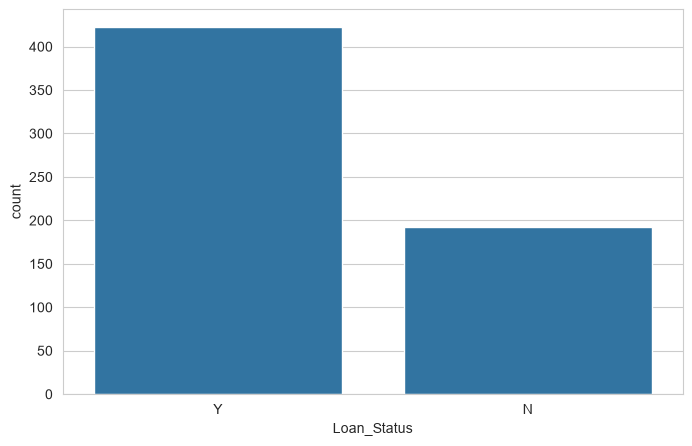

In [137]:
sns.countplot(x='Loan_Status', data=df)

In [138]:
df_cat["Loan_Status"].value_counts(normalize=True)

Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64

In [139]:
#remplacement de la variable cible par des valeurs 0 et 1

In [140]:
df_cat.value_counts(normalize=True)

Loan_ID   Gender  Married  Dependents  Education     Self_Employed  Property_Area  Loan_Status
LP001002  Male    No       0           Graduate      No             Urban          Y              0.001629
LP001003  Male    Yes      1           Graduate      No             Rural          N              0.001629
LP001005  Male    Yes      0           Graduate      Yes            Urban          Y              0.001629
LP001006  Male    Yes      0           Not Graduate  No             Urban          Y              0.001629
LP001008  Male    No       0           Graduate      No             Urban          Y              0.001629
                                                                                                    ...   
LP002978  Female  No       0           Graduate      No             Rural          Y              0.001629
LP002979  Male    Yes      3+          Graduate      No             Rural          Y              0.001629
LP002983  Male    Yes      1           Graduate  

In [141]:
df_cat['Property_Area'].value_counts(normalize=True)

Property_Area
Semiurban    0.379479
Urban        0.328990
Rural        0.291531
Name: proportion, dtype: float64

In [142]:
df_cat.drop(columns=['Loan_ID'], inplace=True)

In [143]:
df_cat.head(5)

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,Urban,Y
1,Male,Yes,1,Graduate,No,Rural,N
2,Male,Yes,0,Graduate,Yes,Urban,Y
3,Male,Yes,0,Not Graduate,No,Urban,Y
4,Male,No,0,Graduate,No,Urban,Y


In [144]:
# Mapping des variables catégorielles à des valeurs numériques
df_cat['Loan_Status']=df_cat['Loan_Status'].map({'Y':1, 'N':0})

In [145]:
df_cat.head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,Urban,1
1,Male,Yes,1,Graduate,No,Rural,0
2,Male,Yes,0,Graduate,Yes,Urban,1
3,Male,Yes,0,Not Graduate,No,Urban,1
4,Male,No,0,Graduate,No,Urban,1


In [146]:
from sklearn.preprocessing import LabelEncoder

In [147]:
# Remplacer les valeurs catégorique
le = LabelEncoder()
for col in df_cat[['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']]:
    df_cat[col] = le.fit_transform(df_cat[col])


In [148]:
df_cat.head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,1,0,0,0,0,2,1
1,1,1,1,0,0,0,0
2,1,1,0,0,1,2,1
3,1,1,0,1,0,2,1
4,1,0,0,0,0,2,1


In [149]:
df_final=pd.concat([df_cat, df_num], axis=1)

In [150]:
df_final.head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,1,0,0,0,0,2,1,5849,0.0,128.0,360.0,1.0
1,1,1,1,0,0,0,0,4583,1508.0,128.0,360.0,1.0
2,1,1,0,0,1,2,1,3000,0.0,66.0,360.0,1.0
3,1,1,0,1,0,2,1,2583,2358.0,120.0,360.0,1.0
4,1,0,0,0,0,2,1,6000,0.0,141.0,360.0,1.0


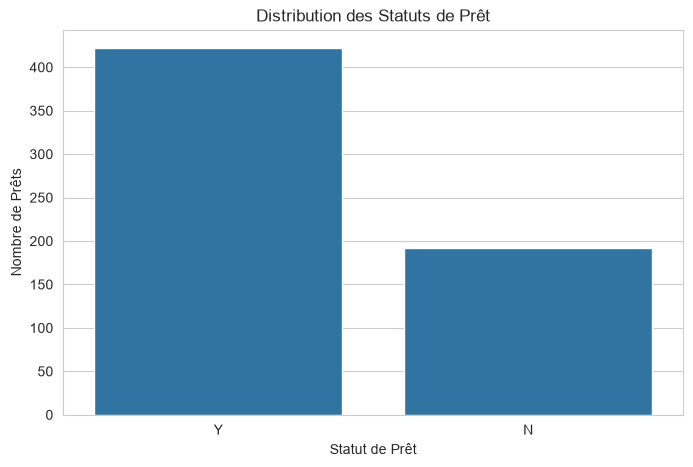

In [151]:
# Analyse exploratoire des données
sns.countplot(x='Loan_Status', data=df_copy)
plt.title('Distribution des Statuts de Prêt')
plt.xlabel('Statut de Prêt')
plt.ylabel('Nombre de Prêts')
plt.show()
#On note que la majorité des prets on été approvés, ce qui indique un déséquilibre de classe dans notre varaible cible. 


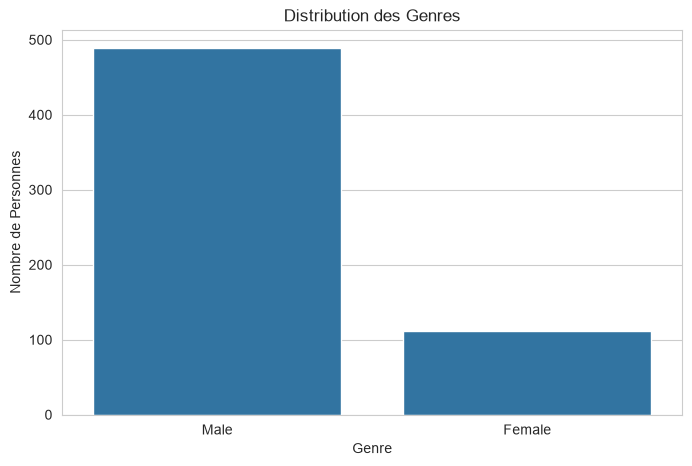

In [152]:
sns.countplot(x='Gender', data=df_copy)
plt.title('Distribution des Genres')
plt.xlabel('Genre')
plt.ylabel('Nombre de Personnes')
plt.show()

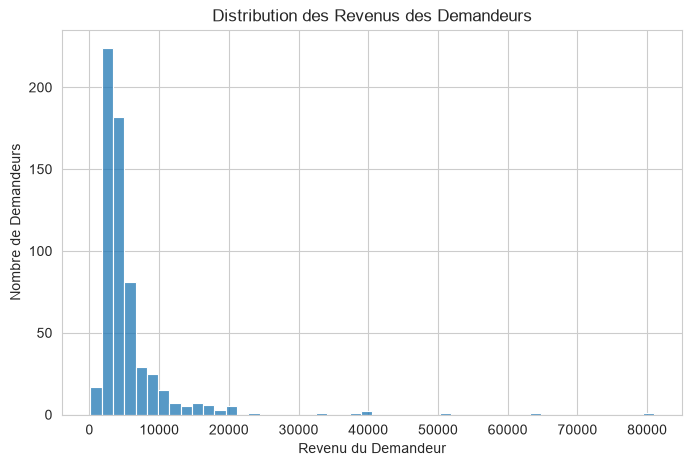

In [153]:
sns.histplot(x='ApplicantIncome', data=df_copy)
plt.title('Distribution des Revenus des Demandeurs')
plt.xlabel('Revenu du Demandeur')
plt.ylabel('Nombre de Demandeurs')
plt.show()

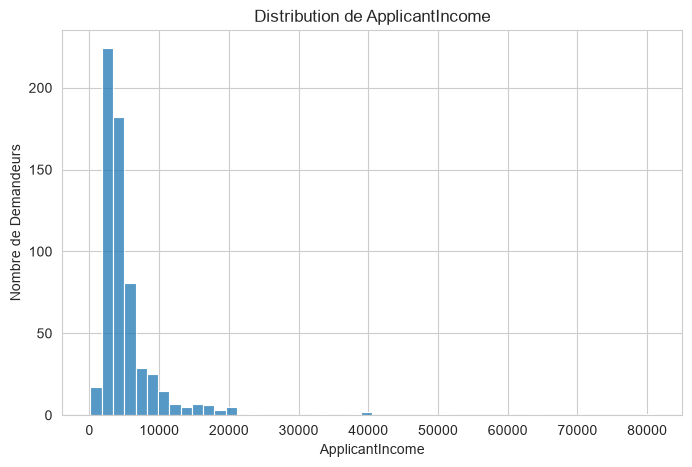

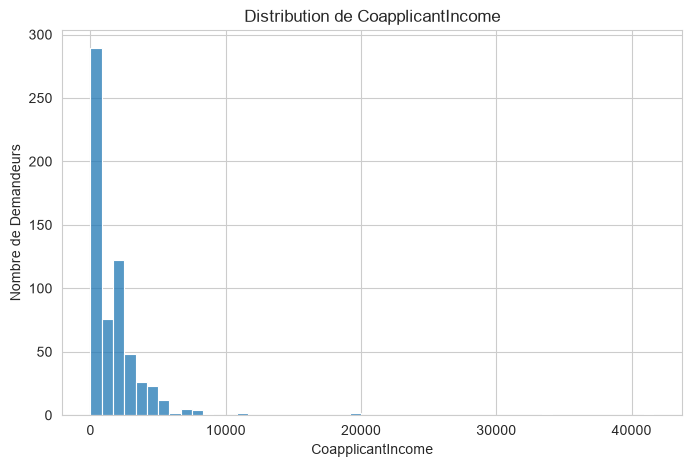

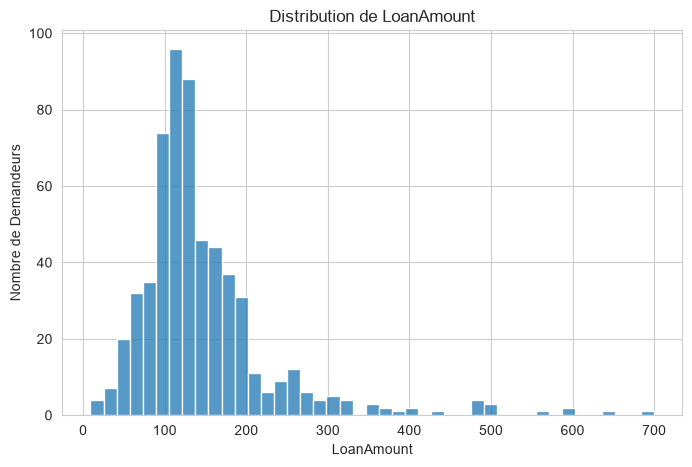

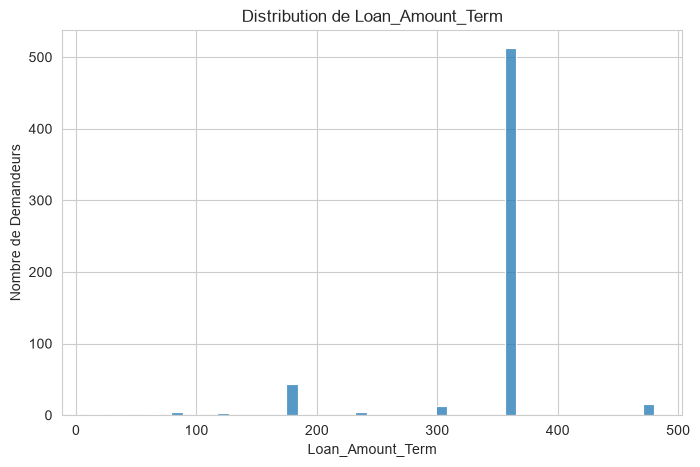

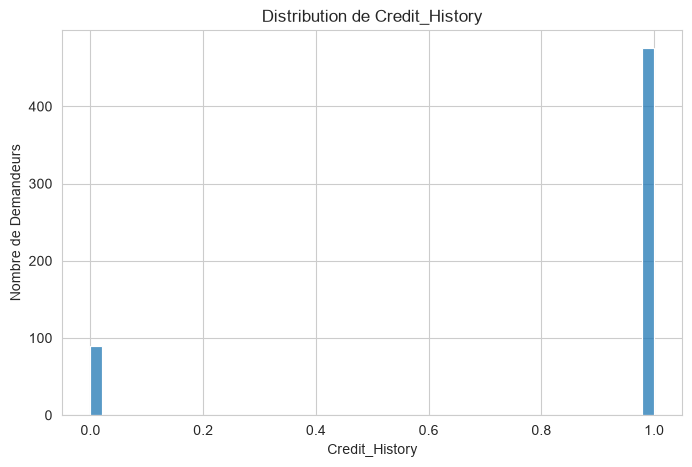

In [154]:
for col in df_num.columns:
    sns.histplot(x=col, data=df_copy)
    plt.title(f'Distribution de {col}')
    plt.xlabel(col)
    plt.ylabel('Nombre de Demandeurs')
    plt.show()

In [155]:
#selon le boxplot que nous avons fait, on peut noter que les
#  variables Revenue du demandeur, Montant du prêt, Revenu du co-demandeur. 
# comportent des valeurs aberrentes, nous allons donc le traiter par la suite.


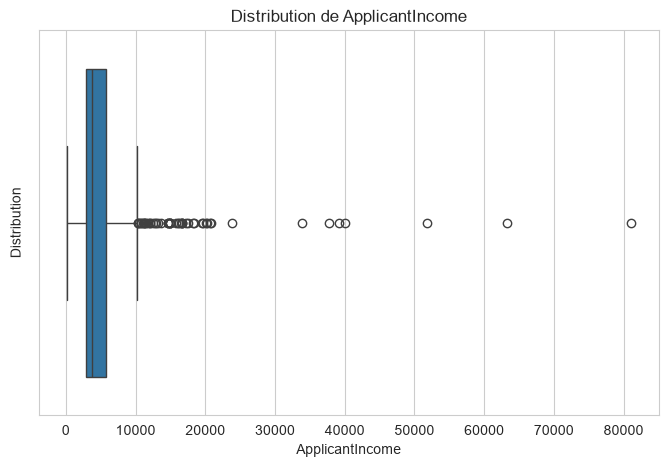

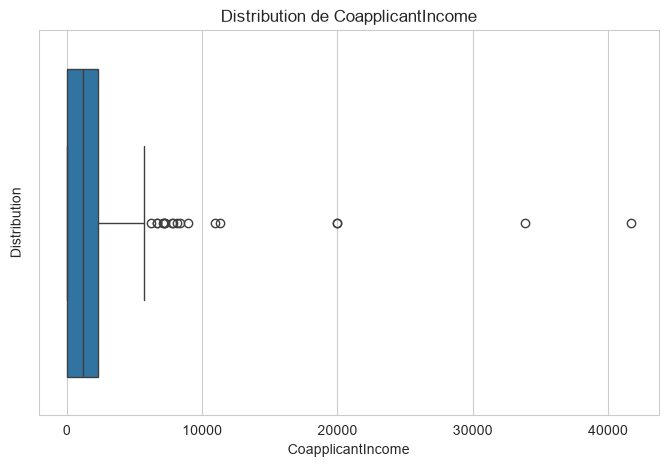

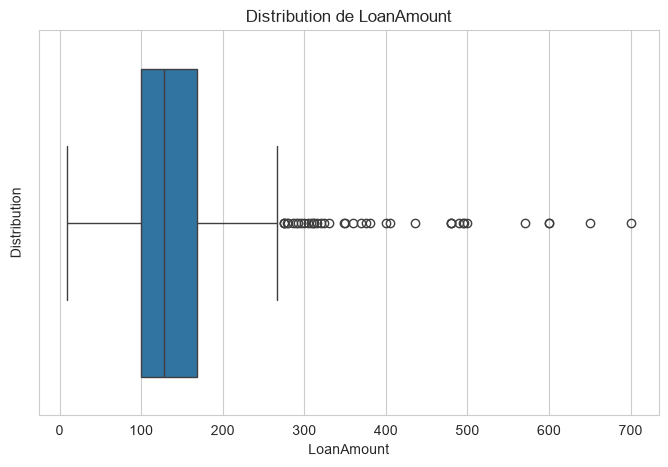

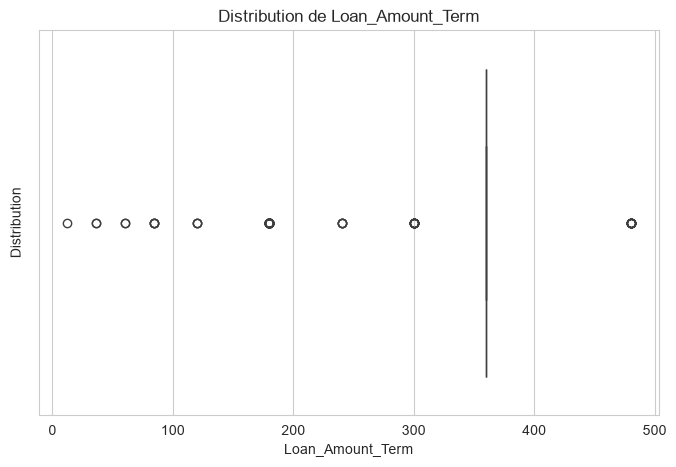

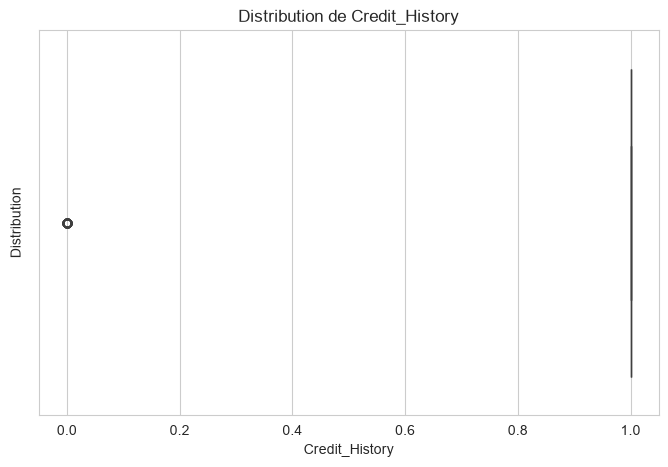

In [156]:
for col in df_num.columns:
    sns.boxplot(x=col, data=df_copy)
    plt.title(f'Distribution de {col}')
    plt.xlabel(col)
    plt.ylabel('Distribution')
    plt.show()

<Axes: xlabel='ApplicantIncome', ylabel='Loan_Status'>

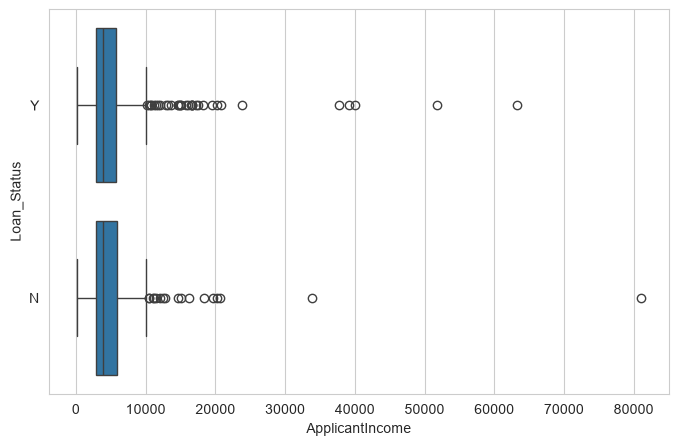

In [157]:
sns.boxplot(x='ApplicantIncome', y='Loan_Status', data=df_copy)
#Revenu du demandeur n'est pas un facteur déterminant pour l'approbation du pret

<Axes: xlabel='CoapplicantIncome', ylabel='Loan_Status'>

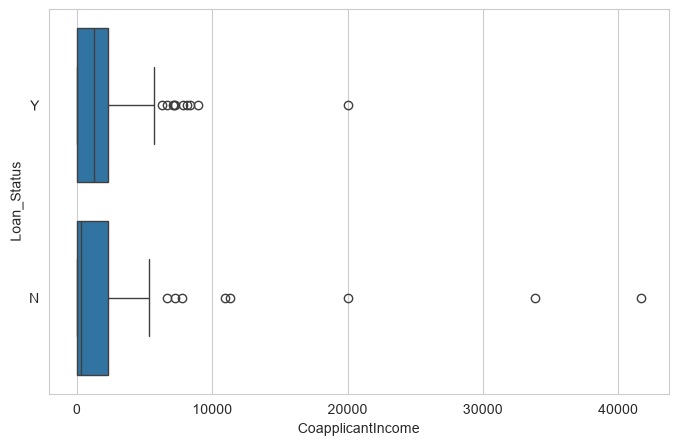

In [158]:
sns.boxplot(x='CoapplicantIncome', y='Loan_Status', data=df_copy)
#Revenu du co_demandeur est un facteur qui influence l'approbation du pret,  on note ici que plus 
# le  revenu du co_demandeur est élevé plus la probabilité d'approbation du pret est élevée.


" . Relation avec la variable cible (Loan_Status)Credit_History et Loan_Status ($r = 0.54$) :   \nInterprétation : C'est la corrélation positive la plus élevée de tout le tableau. Un demandeur ayant un historique \nde crédit positif (remboursement antérieur respecté) a une probabilité nettement plus forte d'obtenir son prêt.  \n Impact modélisation : Ce sera très certainement la variable prédictive (feature) numéro un de vos modèles (arbres de décision, régression logistique ou XGBoost). \n Autres variables et Loan_Status :La quasi-totalité des autres caractéristiques présente une corrélation linéaire directe très faible avec l'accord de prêt \n (entre $-0.086$ pour l'éducation et $+0.091$ pour le statut marital).   Interprétation : Pris isolément de façon linéaire, le revenu, \n le genre ou le nombre de personnes à charge ne garantissent pas l'acceptation ou le refus du prêt. Cela justifie l'utilisation de modèles non linéaires \n (forêts aléatoires, boosting) capables de capturer des

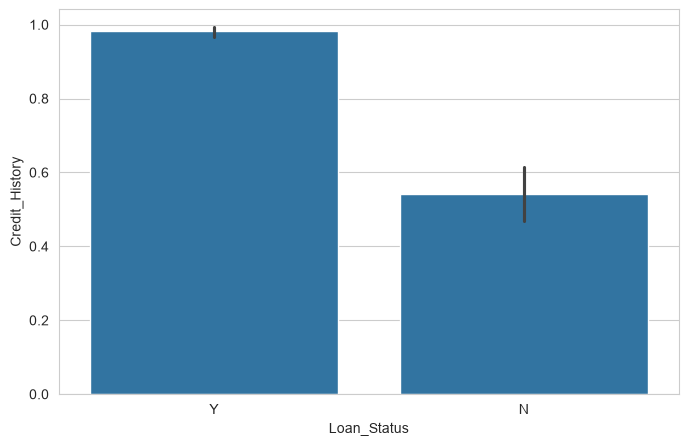

In [159]:
sns.barplot(y='Credit_History', x='Loan_Status', data=df_copy)
#L'historique de crédit est un facteur déterminant pour l'approbation du pret. Plus le crédit historique est proche de 1, 
# plus la probabilité d'approbation du pret est élevée.

""" . Relation avec la variable cible (Loan_Status)Credit_History et Loan_Status ($r = 0.54$) :   
Interprétation : C'est la corrélation positive la plus élevée de tout le tableau. Un demandeur ayant un historique 
de crédit positif (remboursement antérieur respecté) a une probabilité nettement plus forte d'obtenir son prêt.  
 Impact modélisation : Ce sera très certainement la variable prédictive (feature) numéro un de vos modèles (arbres de décision, régression logistique ou XGBoost). 
 Autres variables et Loan_Status :La quasi-totalité des autres caractéristiques présente une corrélation linéaire directe très faible avec l'accord de prêt 
 (entre $-0.086$ pour l'éducation et $+0.091$ pour le statut marital).   Interprétation : Pris isolément de façon linéaire, le revenu, 
 le genre ou le nombre de personnes à charge ne garantissent pas l'acceptation ou le refus du prêt. Cela justifie l'utilisation de modèles non linéaires 
 (forêts aléatoires, boosting) capables de capturer des interactions complexes entre plusieurs critères.

 2. Relations notables entre variables explicatives (Features)ApplicantIncome et LoanAmount ($r = 0.57$) : 

Interprétation : Corrélation modérée à forte, tout à fait cohérente sur le plan métier : plus le demandeur a des revenus élevés, plus le montant du prêt 
demandé est important.   Vigilance (Colinéarité) : Cette relation ne pose pas de problème majeur pour des modèles à base d'arbres, mais pour une 
régression logistique, il peut être judicieux de créer une variable synthétique (ex. le ratio d'endettement : LoanAmount / (ApplicantIncome + CoapplicantIncome)).
Married et Gender ($r = 0.36$) / Married et Dependents ($r = 0.33$) :   Interprétation : Relations démographiques attendues : les personnes mariées ont plus souvent des 
personnes à charge enregistrées dans le dossier.   Absence de multicolinéarité sévère ($r > 0.8$ ou $0.9$) :Aucune paire de variables n'affiche une corrélation prochede 
1. Vous n'avez donc pas de colonnes redondantes à supprimer immédiatement avant la modélisation.   
"""

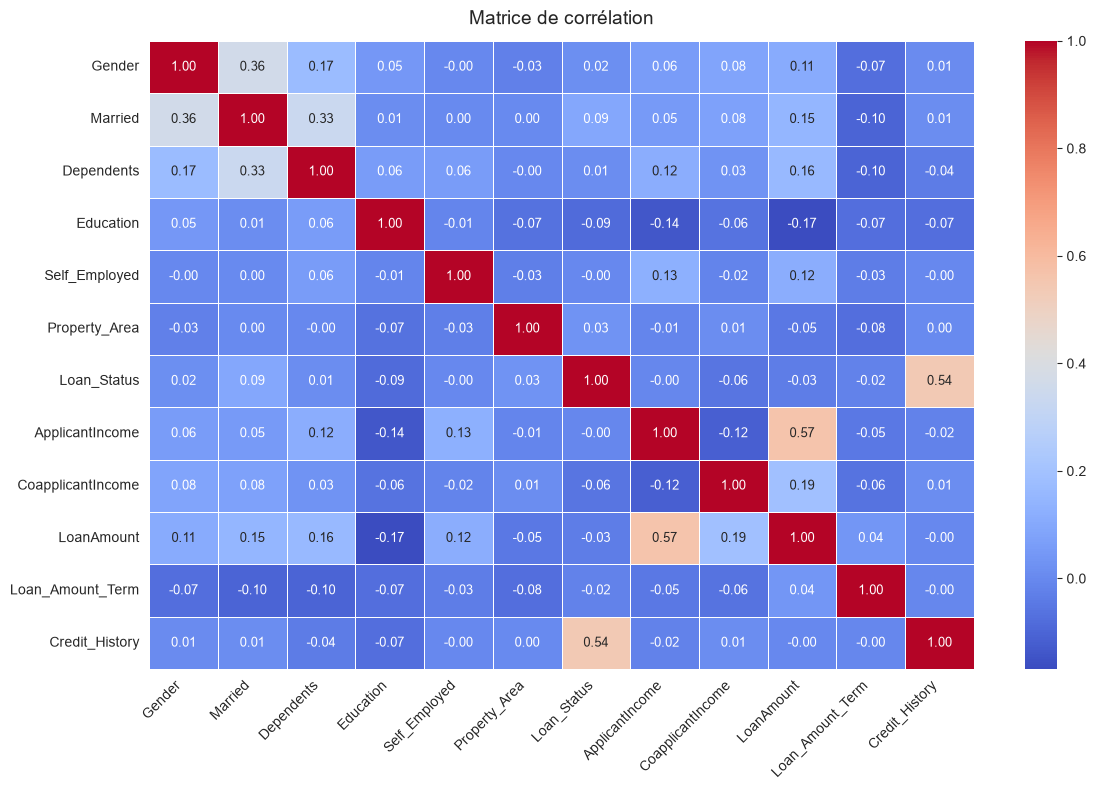

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Définir une taille de figure suffisante (largeur x hauteur)
plt.figure(figsize=(12, 8))

# 2. Configurer la heatmap avec :
#    - fmt='.2f' : arrondit à 2 décimales pour éviter les chevauchements
#    - annot_kws={'size': 10} : réduit légèrement la taille du texte des annotations
#    - linewidths=0.5 : ajoute une séparation nette entre les cases
sns.heatmap(
    df_final.corr(numeric_only=True), 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linewidths=0.5,
    annot_kws={'size': 9}
)

# 3. Incliner les étiquettes pour une lecture claire
plt.title("Matrice de corrélation", fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [161]:
"""traiton les problèmes des valeurs aberrantes (outliers)"""
# Application du log(1 + x) directement sur les variables d'origine
# np.log1p gère les zéros de CoapplicantIncome sans générer d'erreur
df_final['ApplicantIncome_log'] = np.log1p(df_final['ApplicantIncome'])
df_final['CoapplicantIncome_log'] = np.log1p(df_final['CoapplicantIncome'])
df_final['LoanAmount_log'] = np.log1p(df_final['LoanAmount'])

# Suppression des anciennes colonnes non transformées
df_final.drop(columns=['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount'], inplace=True)

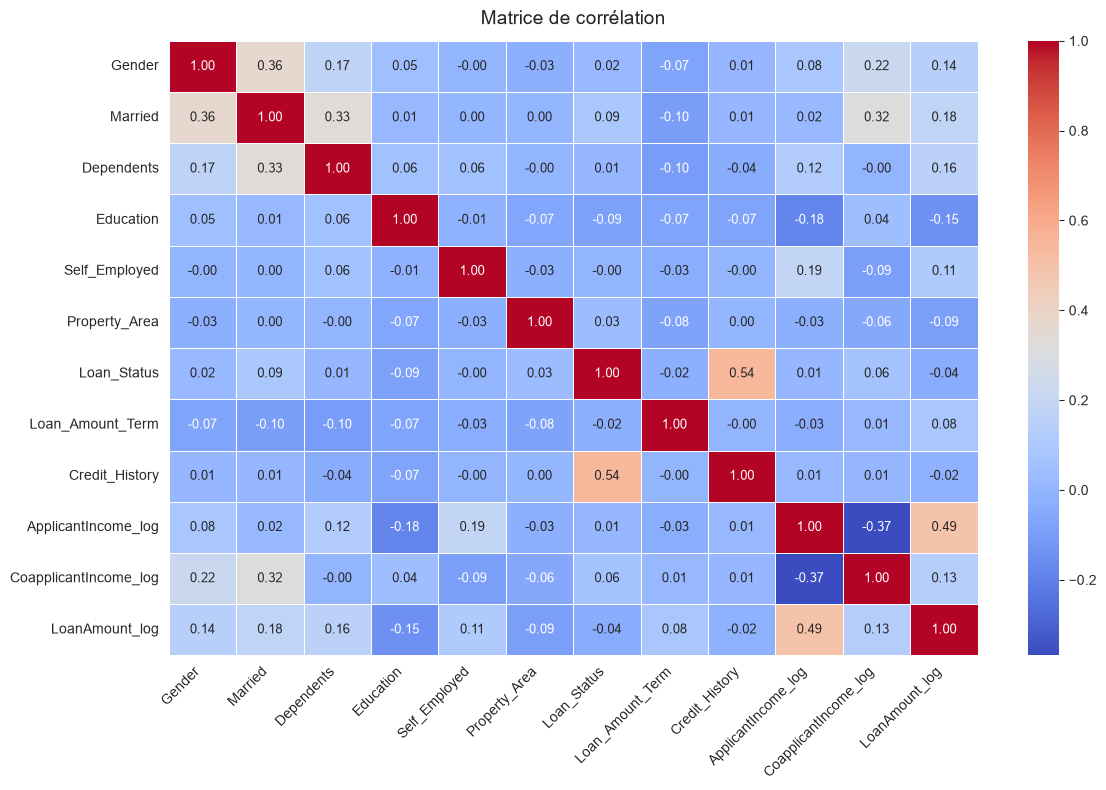

In [162]:
# 1. Définir une taille de figure suffisante (largeur x hauteur)
plt.figure(figsize=(12, 8))

# 2. Configurer la heatmap avec :
#    - fmt='.2f' : arrondit à 2 décimales pour éviter les chevauchements
#    - annot_kws={'size': 10} : réduit légèrement la taille du texte des annotations
#    - linewidths=0.5 : ajoute une séparation nette entre les cases
sns.heatmap(
    df_final.corr(numeric_only=True), 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linewidths=0.5,
    annot_kws={'size': 9}
)

# 3. Incliner les étiquettes pour une lecture claire
plt.title("Matrice de corrélation", fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

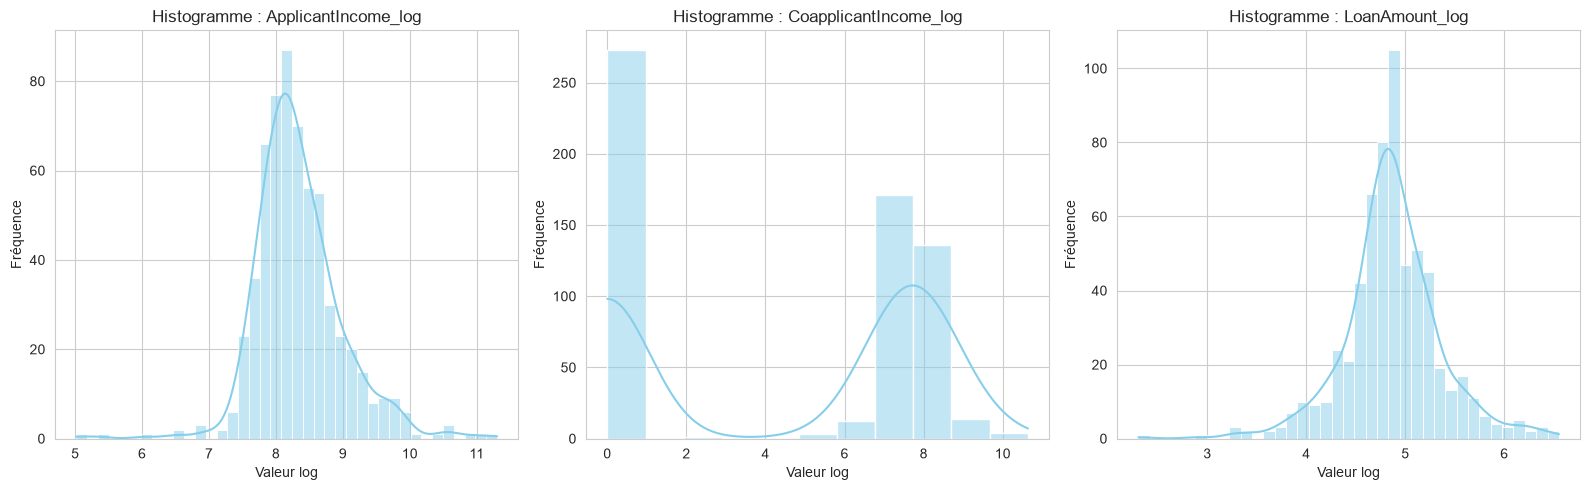

"Histogrammes des variables transformées. L'application de la tranformtion logarithmique à permis de reduire \nl'effet des valeurs aberrantes et rendre la distribution plus symétrique, ce qui est souvent bénéfique pour les modèles de machine learning.\nLa variable CoapplicantIncome_log (Graphique du milieu)Constat : La distribution présente un profil bimodal (deux blocs distincts) :   \nUne barre importante à 0 (les demandeurs seuls, sans co-emprunteur).   Un bloc étalé entre 7 et 9 pour l'ensemble \ndes personnes déclarant un co-emprunteur.   "

In [163]:
cols_log = ['ApplicantIncome_log', 'CoapplicantIncome_log', 'LoanAmount_log']

plt.figure(figsize=(16, 5))

for i, col in enumerate(cols_log, 1):
    plt.subplot(1, 3, i)
    # x=df_final[col] oriente les barres vers le haut (vertical)
    sns.histplot(x=df_final[col], color='skyblue', kde=True)
    plt.title(f'Histogramme : {col}', fontsize=12)
    plt.xlabel('Valeur log')
    plt.ylabel('Fréquence')

plt.tight_layout()
plt.show()

"""Histogrammes des variables transformées. L'application de la tranformtion logarithmique à permis de reduire 
l'effet des valeurs aberrantes et rendre la distribution plus symétrique, ce qui est souvent bénéfique pour les modèles de machine learning.
La variable CoapplicantIncome_log (Graphique du milieu)Constat : La distribution présente un profil bimodal (deux blocs distincts) :   
Une barre importante à 0 (les demandeurs seuls, sans co-emprunteur).   Un bloc étalé entre 7 et 9 pour l'ensemble 
des personnes déclarant un co-emprunteur.   """

GESTION DU DESIQUILIBRE DE CLASSE
ici note un desiquilibre de classe. Car la classe majoritaire sont ceux à qui ont a donnée le pret et la classe minoritaire c'est ceux à qui on a refusé
- **SMOTE** (Synthetic Minority Over-sampling Technique) sur le train set uniquement (jamais sur le test set, pour ne pas biaiser l'évaluation)
- **class_weight, scale_pos_weight** Un modèle avec rééquilibrage (soit via class_weight='balanced' pour une Régression Logistique / Random Forest, soit via scale_pos_weight pour XGBoost).



In [164]:
df_final['Loan_Status'].value_counts(normalize=True)

Loan_Status
1    0.687296
0    0.312704
Name: proportion, dtype: float64

In [165]:
df_final.head()

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status,Loan_Amount_Term,Credit_History,ApplicantIncome_log,CoapplicantIncome_log,LoanAmount_log
0,1,0,0,0,0,2,1,360.0,1.0,8.674197,0.000000,4.859812
1,1,1,1,0,0,0,0,360.0,1.0,8.430327,7.319202,4.859812
2,1,1,0,0,1,2,1,360.0,1.0,8.006701,0.000000,4.204693
3,1,1,0,1,0,2,1,360.0,1.0,7.857094,7.765993,4.795791
4,1,0,0,0,0,2,1,360.0,1.0,8.699681,0.000000,4.955827


In [166]:
X=df_final.drop(columns=['Loan_Status'])
y=df_final['Loan_Status']

In [167]:
from imblearn.over_sampling import SMOTE

In [168]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [169]:
# Instancier le standardiseur
scaler = StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [170]:
smote= SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Avant SMOTE : {y_train.value_counts().to_dict()}")
print(f"Après SMOTE : {pd.Series(y_train_smote).value_counts().to_dict()}")




Avant SMOTE : {1: 337, 0: 154}
Après SMOTE : {1: 337, 0: 337}


Analyse multivariée avec L'ACP
Construction de l'ACP

In [171]:
#importation des packages
from sklearn.decomposition import PCA


In [172]:
#reduction de dimensionnalité avec le PCA
pca= PCA()
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [173]:
#clacule des axe factoriels. Choisir les axes factoriel
n = pca.n_components_
comp = pd.DataFrame({
    "Dimension": ["Dim" + str(x + 1) for x in range(n)],
    "Valeur propre": pca.explained_variance_,
    "% variance expliquée": np.round(pca.explained_variance_ratio_ * 100, 1),
    "% cum. var. expliquée": np.round(np.cumsum(pca.explained_variance_ratio_) * 100, 1)
})
comp

,Dimension,Valeur propre,% variance expliquée,% cum. var. expliquée
0,Dim1,1.932798,17.5,17.5
1,Dim2,1.746445,15.8,33.4
2,Dim3,1.215680,11.0,44.4
3,Dim4,1.065144,9.7,54.1
4,Dim5,0.984337,8.9,63.0
5,Dim6,0.886606,8.0,71.0
6,Dim7,0.845990,7.7,78.7
7,Dim8,0.807449,7.3,86.0
8,Dim9,0.739597,6.7,92.8
9,Dim10,0.533712,4.8,97.6


Text(3.25, 10, '9.1%')

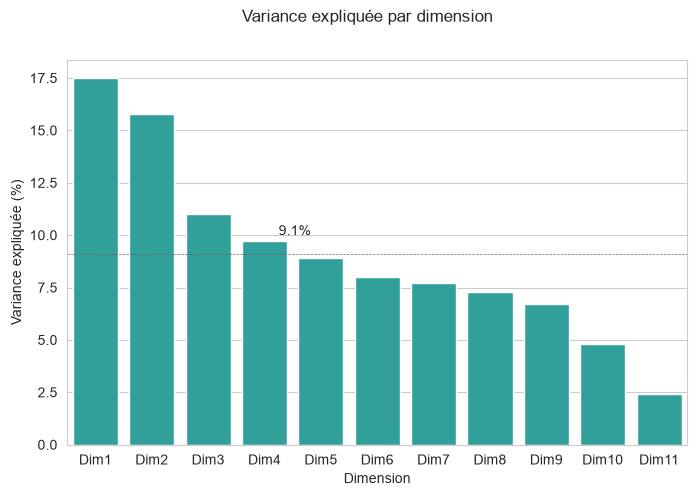

In [174]:
# Scree plot pour choisir le nombre de composantes principales vu que moi j'ai 11 variable 100/11=9.1%
g_comp = sns.barplot(x = "Dimension", 
                y = "% variance expliquée",
                color = "lightseagreen",
                data = comp)
g_comp.set(ylabel = "Variance expliquée (%)")
g_comp.figure.suptitle("Variance expliquée par dimension")
plt.axhline(y = 9.1, linewidth = .5, color = "dimgray", linestyle = "--") # 9.1 = 100 / 11 (nb dimensions)
plt.text(3.25, 10, "9.1%")

In [175]:
# Corrélations variables / axes (coordonnées des variables)
coord = pca.components_.T * np.sqrt(pca.explained_variance_)
noms_pc = [f"PC{i+1}" for i in range(pca.n_components_)]

# Cosinus carré : qualité de représentation
df_cos2 = pd.DataFrame(coord**2, index=X_train.columns, columns=noms_pc)

# Contributions (%) : part de chaque variable dans la construction de l'axe
df_contrib = pd.DataFrame(pca.components_.T**2 * 100, index=X_train.columns, columns=noms_pc)

print(df_cos2.round(2))
print(df_contrib.round(1))

"""Interprétation des axes

PC1, le profil familial : Married (0,52), Gender (0,41), LoanAmount (0,35) et Dependents (0,32). Cet axe oppose plutôt les demandeurs mariés 
avec des personnes à charge, qui empruntent des montants plus élevés, aux célibataires.
PC2, l’axe des revenus : ApplicantIncome (0,67), CoapplicantIncome (0,37) et LoanAmount (0,23). C’est la dimension financière.
PC3, la durée du prêt : surtout Loan_Amount_Term (0,38), avec un peu de CoapplicantIncome et d’Education. Cet axe est moins net.
PC4, la zone géographique : Property_Area (0,58), et un peu de Credit_History (0,23).

Ce qu’il faut remarquer

Credit_History est mal représenté sur les 4 premiers axes : il est surtout sur PC5 (0,56). C’est important, car dans ce type de jeu de données,
 l’historique de crédit est souvent la variable la plus prédictive du statut du prêt. Avec seulement 4 dimensions, vous perdriez une bonne partie de cette information.
Self_Employed et Education sont aussi faiblement représentés sur PC1 à PC4. Leur information est dispersée sur les autres axes.

Cela confirme ce qu’on voyait sur le graphique des valeurs propres : les variables sont peu corrélées, donc l’ACP résume mal. Pour un modèle de prédiction,
 je garderais les variables d’origine plutôt que les composantes."""

                        PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8   PC9  \
Gender                 0.41  0.04  0.00  0.02  0.00  0.00  0.01  0.11  0.34   
Married                0.52  0.11  0.00  0.02  0.00  0.00  0.00  0.01  0.00   
Dependents             0.32  0.00  0.11  0.00  0.00  0.19  0.04  0.22  0.02   
Education              0.00  0.14  0.19  0.16  0.04  0.13  0.08  0.21  0.04   
Self_Employed          0.04  0.14  0.09  0.01  0.26  0.09  0.25  0.10  0.03   
Property_Area          0.02  0.00  0.05  0.58  0.09  0.00  0.22  0.00  0.03   
Loan_Amount_Term       0.03  0.02  0.38  0.03  0.01  0.29  0.17  0.04  0.03   
Credit_History         0.01  0.00  0.07  0.23  0.56  0.07  0.04  0.03  0.00   
ApplicantIncome_log    0.13  0.67  0.00  0.00  0.01  0.00  0.01  0.05  0.00   
CoapplicantIncome_log  0.11  0.37  0.21  0.00  0.01  0.10  0.02  0.01  0.08   
LoanAmount_log         0.35  0.23  0.11  0.01  0.00  0.01  0.01  0.04  0.17   

                       PC10  PC11  
Gender         

'Interprétation des axes\n\nPC1, le profil familial : Married (0,52), Gender (0,41), LoanAmount (0,35) et Dependents (0,32). Cet axe oppose plutôt les demandeurs mariés \navec des personnes à charge, qui empruntent des montants plus élevés, aux célibataires.\nPC2, l’axe des revenus : ApplicantIncome (0,67), CoapplicantIncome (0,37) et LoanAmount (0,23). C’est la dimension financière.\nPC3, la durée du prêt : surtout Loan_Amount_Term (0,38), avec un peu de CoapplicantIncome et d’Education. Cet axe est moins net.\nPC4, la zone géographique : Property_Area (0,58), et un peu de Credit_History (0,23).\n\nCe qu’il faut remarquer\n\nCredit_History est mal représenté sur les 4 premiers axes : il est surtout sur PC5 (0,56). C’est important, car dans ce type de jeu de données,\n l’historique de crédit est souvent la variable la plus prédictive du statut du prêt. Avec seulement 4 dimensions, vous perdriez une bonne partie de cette information.\nSelf_Employed et Education sont aussi faiblement rep

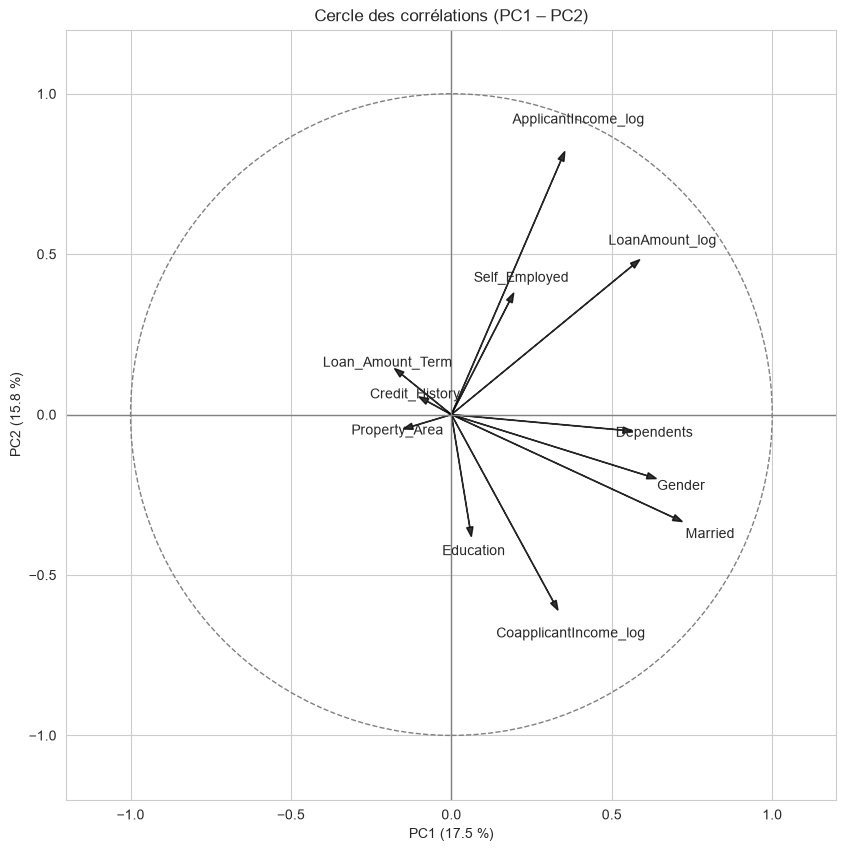

In [176]:
# Coordonnées des variables = corrélations avec les axes
coord = pca.components_.T * np.sqrt(pca.explained_variance_)
noms = X_train.columns
var_exp = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(10, 10))

for i in range(len(noms)):
    plt.arrow(0, 0, coord[i, 0], coord[i, 1], color="k", alpha=0.8,
              head_width=0.02, length_includes_head=True)
    plt.text(coord[i, 0] * 1.12, coord[i, 1] * 1.12, noms[i],
             ha="center", va="center", fontsize=10)

cercle = plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--")
plt.gca().add_artist(cercle)

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.axhline(0, color="gray", linewidth=1)
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel(f"PC1 ({var_exp[0]:.1f} %)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f} %)")
plt.title("Cercle des corrélations (PC1 – PC2)")
plt.gca().set_aspect("equal")
plt.show()

In [177]:
"""Axe 1 (horizontal, 17,5 %) : le profil familial
Married, Gender, Dependents et LoanAmount_log pointent tous vers la droite. Cela oppose les demandeurs mariés, 
majoritairement des hommes avec des personnes à charge, qui empruntent des montants plus élevés (à droite), aux demandeurs seuls (à gauche).

Married et Gender sont presque alignés, donc ces deux variables sont fortement corrélées dans vos données.

Axe 2 (vertical, 15,8 %) : l’origine des revenus
C’est l’axe le plus intéressant. ApplicantIncome_log pointe vers le haut et CoapplicantIncome_log vers le bas : 
elles s’opposent. Autrement dit, quand le demandeur principal gagne beaucoup, le co-demandeur gagne peu, et inversement. 
Il y a une forme de complémentarité dans le foyer. Cet axe oppose donc les foyers à un revenu principal aux foyers où le co-demandeur contribue beaucoup.

Les positions intermédiaires

LoanAmount_log est entre ApplicantIncome et le groupe familial. Le montant emprunté augmente à la fois avec le revenu du demandeur et avec la taille de la famille.
Self_Employed va dans le sens d’ApplicantIncome, mais sa flèche est courte, donc l’interprétation reste prudente.
Education pointe vers le bas, mais la flèche est assez courte. Attention aussi au codage : selon l’encodage 0/1, le sens peut être « diplômé » ou « non diplômé ».
 Vérifiez quelle valeur correspond à quoi avant de conclure.

Les variables à ne pas interpréter ici
Credit_History, Property_Area et Loan_Amount_Term ont des flèches très courtes, près du centre. Elles sont mal représentées sur ce plan,
 et leur information est sur d’autres axes (PC3, PC4 et PC5). C’est notable pour Credit_History, qui est souvent déterminante pour l’acceptation d’un prêt."""

'Axe 1 (horizontal, 17,5 %) : le profil familial\nMarried, Gender, Dependents et LoanAmount_log pointent tous vers la droite. Cela oppose les demandeurs mariés, \nmajoritairement des hommes avec des personnes à charge, qui empruntent des montants plus élevés (à droite), aux demandeurs seuls (à gauche).\n\nMarried et Gender sont presque alignés, donc ces deux variables sont fortement corrélées dans vos données.\n\nAxe 2 (vertical, 15,8 %) : l’origine des revenus\nC’est l’axe le plus intéressant. ApplicantIncome_log pointe vers le haut et CoapplicantIncome_log vers le bas : \nelles s’opposent. Autrement dit, quand le demandeur principal gagne beaucoup, le co-demandeur gagne peu, et inversement. \nIl y a une forme de complémentarité dans le foyer. Cet axe oppose donc les foyers à un revenu principal aux foyers où le co-demandeur contribue beaucoup.\n\nLes positions intermédiaires\n\nLoanAmount_log est entre ApplicantIncome et le groupe familial. Le montant emprunté augmente à la fois avec

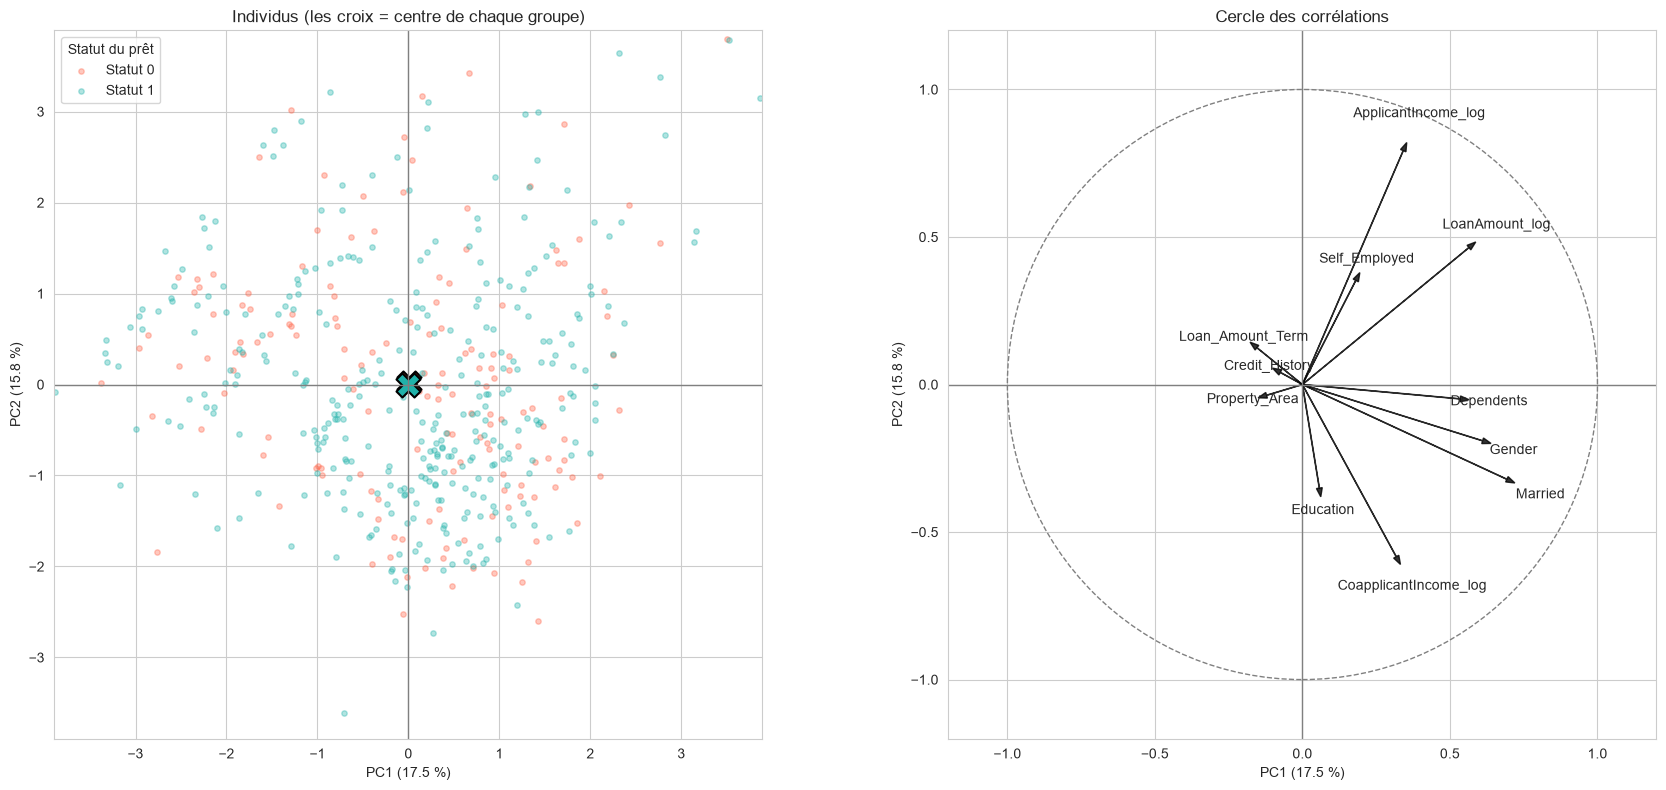

In [178]:
coord = pca.components_.T * np.sqrt(pca.explained_variance_)
noms = X_train.columns
var_exp = pca.explained_variance_ratio_ * 100
y_arr = np.asarray(y_train)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# --- Gauche : individus ---
couleurs = {0: "tomato", 1: "lightseagreen"}
for classe in np.unique(y_arr):
    pts = X_train_pca[y_arr == classe]
    ax1.scatter(pts[:, 0], pts[:, 1], color=couleurs[classe],
                alpha=0.35, s=15, label=f"Statut {classe}")
    # Centre du groupe
    ax1.scatter(pts[:, 0].mean(), pts[:, 1].mean(), color=couleurs[classe],
                marker="X", s=300, edgecolor="black", linewidth=1.5)

lim = np.percentile(np.abs(X_train_pca[:, :2]), 99) * 1.1
ax1.set_xlim(-lim, lim)
ax1.set_ylim(-lim, lim)
ax1.axhline(0, color="gray", linewidth=1)
ax1.axvline(0, color="gray", linewidth=1)
ax1.set_xlabel(f"PC1 ({var_exp[0]:.1f} %)")
ax1.set_ylabel(f"PC2 ({var_exp[1]:.1f} %)")
ax1.set_title("Individus (les croix = centre de chaque groupe)")
ax1.set_aspect("equal")
ax1.legend(title="Statut du prêt")

# --- Droite : cercle des corrélations ---
for i in range(len(noms)):
    ax2.arrow(0, 0, coord[i, 0], coord[i, 1], color="k", alpha=0.8,
              head_width=0.02, length_includes_head=True)
    ax2.text(coord[i, 0] * 1.12, coord[i, 1] * 1.12, noms[i],
             ha="center", va="center", fontsize=10)

ax2.add_artist(plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--"))
ax2.set_xlim(-1.2, 1.2)
ax2.set_ylim(-1.2, 1.2)
ax2.axhline(0, color="gray", linewidth=1)
ax2.axvline(0, color="gray", linewidth=1)
ax2.set_xlabel(f"PC1 ({var_exp[0]:.1f} %)")
ax2.set_ylabel(f"PC2 ({var_exp[1]:.1f} %)")
ax2.set_title("Cercle des corrélations")
ax2.set_aspect("equal")

plt.tight_layout()
plt.show()

## Étape 7 - Modélisation : Détection d'anomalies

### Algorithmes supervisés : Random Forest, XGBoost, Régression logistique

In [179]:

models = {}
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (XGBoost) : {scale_pos_weight:.2f}")

# Régression logistique (entraînée sur les données rééquilibrées par SMOTE)
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_smote, y_train_smote)
models['Régression Logistique'] = log_reg

# Random Forest (entraîné sur les données rééquilibrées par SMOTE)
rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42)
rf.fit(X_train_smote, y_train_smote)
models['Random Forest'] = rf

# XGBoost (utilise scale_pos_weight sur les données originales, sans SMOTE, approche alternative)
xgb_clf = xgb.XGBClassifier(
    n_estimators=200, scale_pos_weight=scale_pos_weight, eval_metric='logloss',
    random_state=42
)
xgb_clf.fit(X_train_scaled, y_train)
models['XGBoost'] = xgb_clf

print("Modèles supervisés entraînés :", list(models.keys()))


scale_pos_weight (XGBoost) : 0.46
Modèles supervisés entraînés : ['Régression Logistique', 'Random Forest', 'XGBoost']


### Algorithmes non supervisés : Isolation Forest, Kmeans

l'accuracy est totalemement inadequate pour évaluer les modèles sur un jeu de données déséquilibré. Il est donc préférable d'utiliser des métriques comme le **F1-score, la précision, le rappel et l'AUC-ROC** pour une évaluation plus complète.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# ==============================================================================
# 1. ÉVALUATION DES 3 MODÈLES SUPERVISÉS DÉJÀ ENTRAÎNÉS
# ==============================================================================
resultats = []

for nom, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    resultats.append({
        "Type": "Supervisé",
        "Algorithme": nom,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4)
    })

# ==============================================================================
# 2. ENTRAÎNEMENT ET ÉVALUATION DES 2 MÉTHODES NON SUPERVISÉES
# ==============================================================================

# A. Isolation Forest (Détection d'anomalies / profils atypiques)
taux_contamination = (y_train == 0).mean()
iso_forest = IsolationForest(contamination=taux_contamination, random_state=42)
iso_forest.fit(X_train_scaled)

# 1 = Normal (Accord), 0 = Atypique (Refus)
iso_pred = np.where(iso_forest.predict(X_test_scaled) == 1, 1, 0)
iso_scores = iso_forest.decision_function(X_test_scaled)

resultats.append({
    "Type": "Non Supervisé",
    "Algorithme": "Isolation Forest",
    "Accuracy": round(accuracy_score(y_test, iso_pred), 4),
    "Precision": round(precision_score(y_test, iso_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test, iso_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, iso_pred, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, iso_scores), 4)
})

# B. K-Means (Clustering k=2)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)
clusters = kmeans.predict(X_test_scaled)

# Alignement de l'étiquette de cluster avec la classe majoritaire réelle
if accuracy_score(y_test, 1 - clusters) > accuracy_score(y_test, clusters):
    clusters = 1 - clusters

resultats.append({
    "Type": "Non Supervisé",
    "Algorithme": "K-Means (k=2)",
    "Accuracy": round(accuracy_score(y_test, clusters), 4),
    "Precision": round(precision_score(y_test, clusters, zero_division=0), 4),
    "Recall": round(recall_score(y_test, clusters, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, clusters, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, clusters), 4)
})

# ==============================================================================
# 3. AFFICHAGE DU TABLEAU DE SYNTHÈSE UNIQUE
# ==============================================================================
df_comparatif = pd.DataFrame(resultats)
print("\n" + "="*80)
print("TABLEAU COMPARATIF DES 5 MODÈLES (3 SUPERVISÉS ET 2 NON SUPERVISÉS)")
print("="*80)
print(df_comparatif.to_string(index=False))




TABLEAU COMPARATIF DES 5 MODÈLES (3 SUPERVISÉS ET 2 NON SUPERVISÉS)
         Type            Algorithme  Accuracy  Precision  Recall  F1-Score  ROC-AUC
    Supervisé Régression Logistique    0.8455     0.8438  0.9529    0.8950   0.8412
    Supervisé         Random Forest    0.7967     0.8333  0.8824    0.8571   0.7924
    Supervisé               XGBoost    0.8130     0.8780  0.8471    0.8623   0.7796
Non Supervisé      Isolation Forest    0.6423     0.7531  0.7176    0.7349   0.7115
Non Supervisé         K-Means (k=2)    0.6098     0.7403  0.6706    0.7037   0.5721


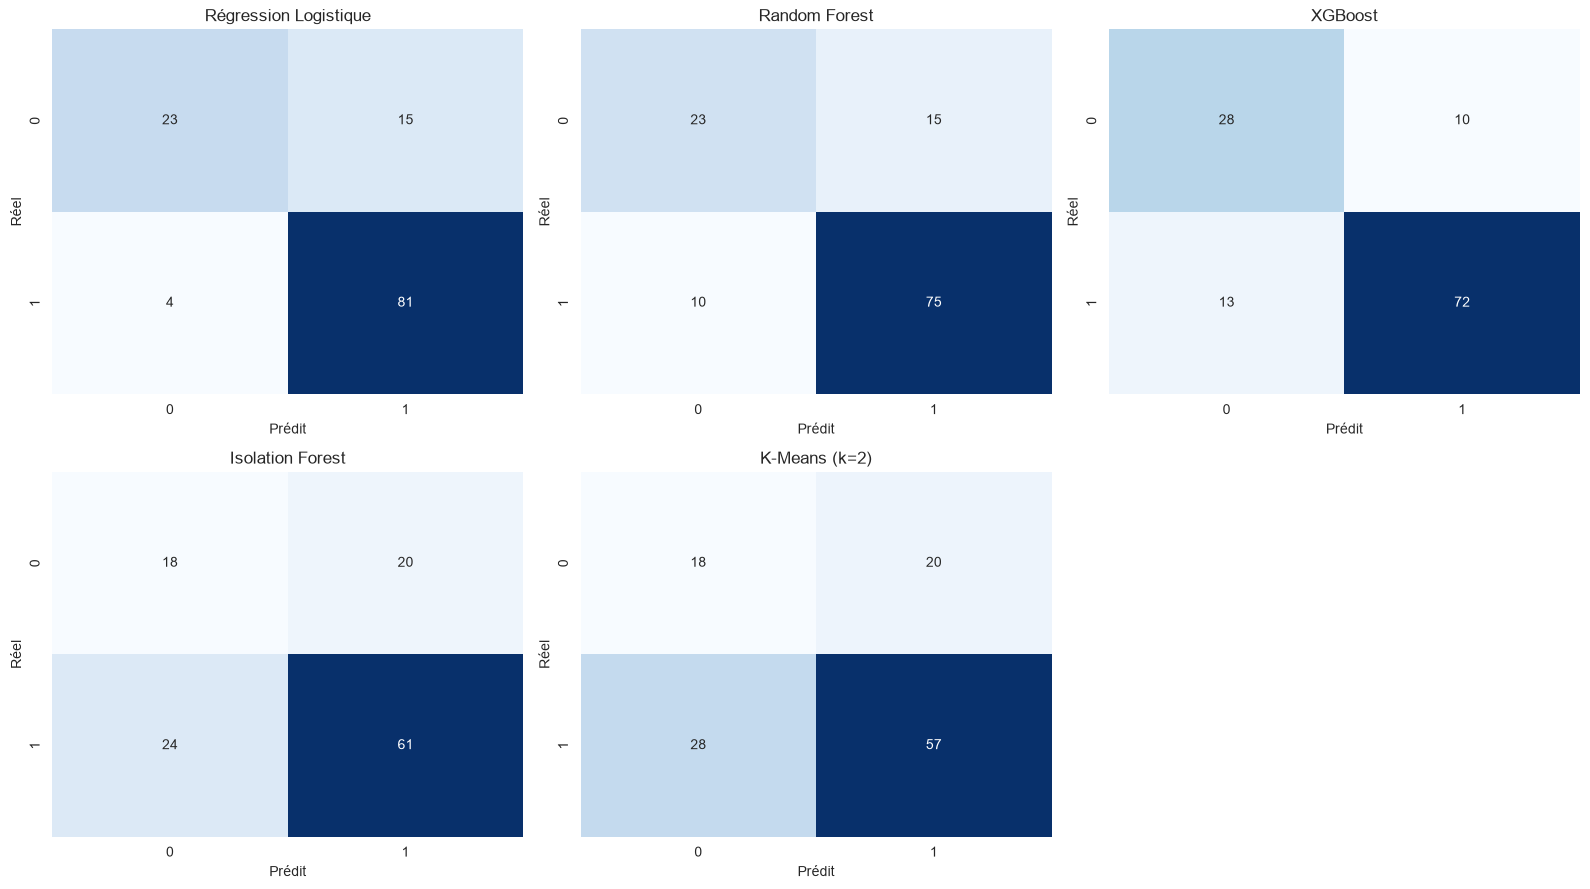

In [ ]:
# Matrices de confusion pour chaque modèle
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
preds_dict = {
    'Régression Logistique': models['Régression Logistique'].predict(X_test_scaled),
    'Random Forest': models['Random Forest'].predict(X_test_scaled),
    'XGBoost': models['XGBoost'].predict(X_test_scaled),
    'Isolation Forest': iso_pred,
    'K-Means (k=2)': clusters
}

for ax, (name, pred) in zip(axes.flatten(), preds_dict.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel')
axes.flatten()[-1].axis('off')   # cache la 6e case vide


plt.tight_layout()
plt.show()


"""1. Analyse détaillée modèle par modèleA. Régression Logistique (Le choix du volume commercial)
Vrais Négatifs (VN) : 23 | Faux Positifs (FP) : 15   Faux Négatifs (FN) : 4 | Vrais Positifs (VP) : 81  
Constat :Il n'a refusé à tort que 4 dossiers viables sur 85, ce qui explique son rappel record de 95,29 %.   En revanche, il a accordé un prêt à 15 profils insolvables 
sur 38. C'est un modèle commercialement très agressif qui maximise l'octroi.   B. XGBoost (Le choix de la sécurité financière et de la prudence) 
Vrais Négatifs (VN) : 28 | Faux Positifs (FP) : 10   Faux Négatifs (FN) : 13 | Vrais Positifs (VP) : 72   Constat :C'est le modèle qui gère le mieux le
risque crédit : il ne commet que 10 erreurs d'accord sur les profils à risque (contre 15 pour les deux autres).   
Cela justifie sa précision maximale (87,80 %) : lorsqu'il valide un dossier, la banque est certaine à près de 88 % que le client remboursera.
La contrepartie est qu'il est plus sévère : il rejette 13 bons dossiers. 

Argumentaire rédigé pour votre rapport
« L'examen des matrices de confusion non supervisées confirme les enseignements de l'ACP. K-Means et Isolation Forest identifient 
chacun 18 refus réels sur 38 sans supervision, mais au prix d'un nombre élevé de faux négatifs (24 pour Isolation Forest et 28 pour K-Means).
Dans l'espace multidimensionnel, un dossier atypique ne correspond pas nécessairement à un client insolvable : un emprunteur à très haut revenu 
sans historique d'impayé est géométriquement marginal, mais financièrement solide. Cela démontre que l'apprentissage non supervisé seul ne peut 
piloter l'octroi de crédit, mais qu'Isolation Forest constitue un outil pertinent de filtrage 
préalable pour signaler les dossiers singuliers à un analyste humain.

"""

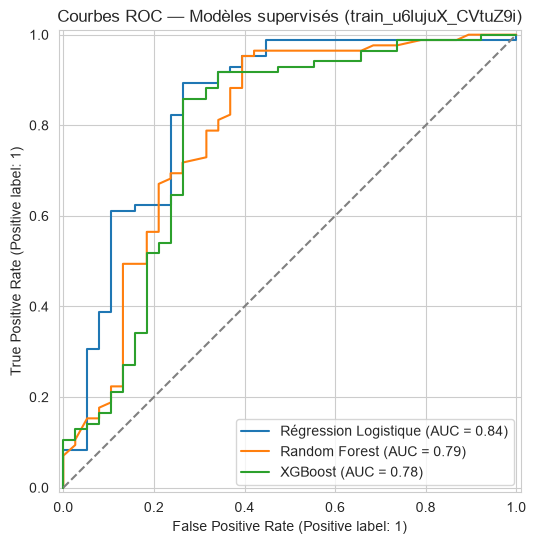

In [ ]:
# Courbes ROC (modèles supervisés)
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax, name=name)
plt.title("Courbes ROC — Modèles supervisés (train_u6lujuX_CVtuZ9i)")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.show()

"""Diagonale pointillée grise : Représente le hasard complet AUC = 0.5. Plus une courbe monte vite vers le coin supérieur 
gauche (0, 1), plus le modèle est performant. 

Synthèse rédigée 
La comparaison des courbes ROC confirme la hiérarchie établie lors du benchmarking. La Régression Logistique rééquilibrée avec SMOTE surpasse 
les modèles ensemblistes avec une aire sous la courbe de 0,84, contre 0,79 pour Random Forest et 0,78 pour XGBoost. La régularité
 de la courbe bleue démontre la robustesse de la frontière linéaire guidée par l'historique de 
crédit, tandis que XGBoost se distingue par une sélectivité accrue dans les zones à très faible tolérance au risque (FPR < 0,10). """


INTERPRETABILITE

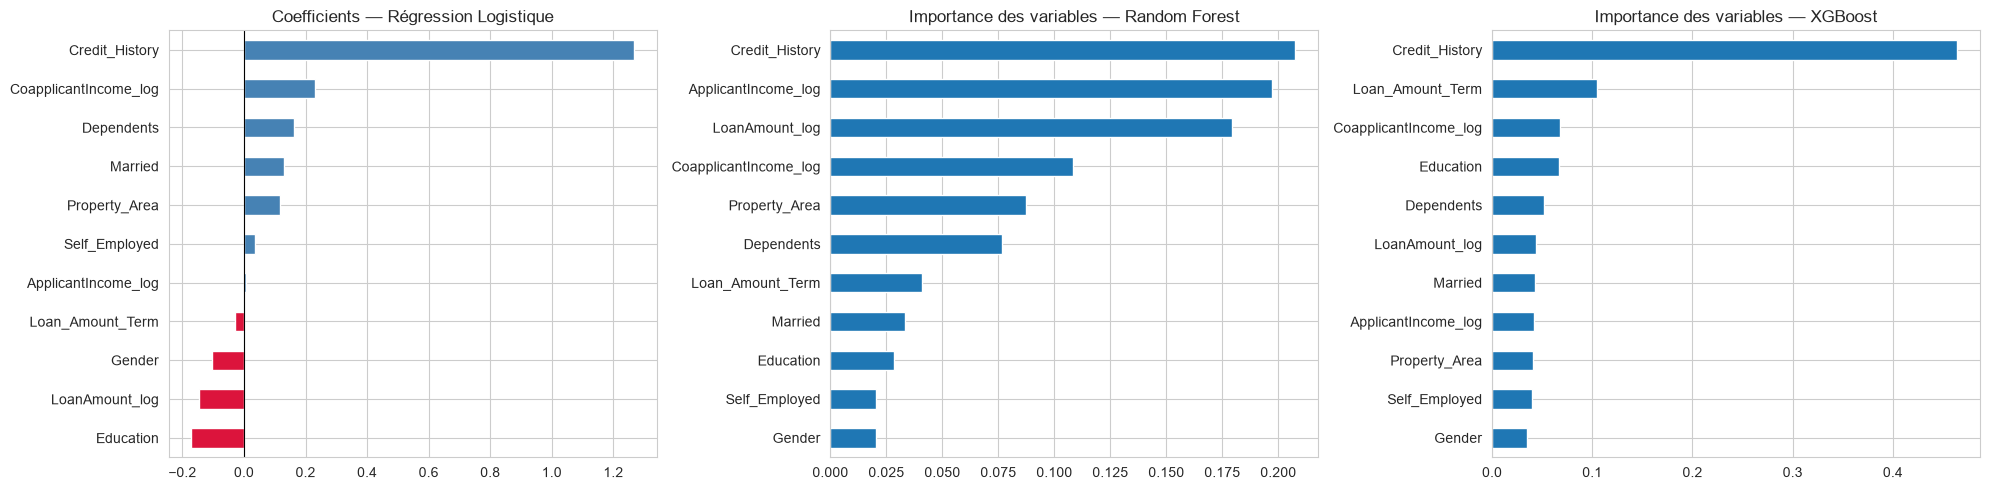

In [ ]:

features = X_train.columns
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

log_reg_coefs = pd.Series(models['Régression Logistique'].coef_[0], index=features).sort_values()
colors = ['crimson' if c < 0 else 'steelblue' for c in log_reg_coefs]
log_reg_coefs.plot(kind='barh', ax=axes[0], color=colors, title="Coefficients — Régression Logistique")
axes[0].axvline(0, color='black', linewidth=0.8)

rf_importances = pd.Series(models['Random Forest'].feature_importances_, index=features).sort_values()
rf_importances.plot(kind='barh', ax=axes[1], title="Importance des variables — Random Forest")

xgb_importances = pd.Series(models['XGBoost'].feature_importances_, index=features).sort_values()
xgb_importances.plot(kind='barh', ax=axes[2], title="Importance des variables — XGBoost")

plt.tight_layout()
plt.show()

"""L'analyse de l'importance des variables confirme que la décision d'octroi repose massivement 
sur l'historique de crédit (Credit_History), qui constitue le prédicteur dominant pour l'ensemble 
des trois algorithmes supervisés. Dans la Régression Logistique, son coefficient positif unitaire dépasse nettement 
toutes les autres covariables. Si le Random Forest tend à diluer l'importance sur les variables financières continues 
en raison du tirage aléatoire des descripteurs (ApplicantIncome_log, LoanAmount_log), XGBoost concentre près de 47 % de son
 gain décisionnel sur le seul historique d'impayé. Cette primauté explique la robustesse des modèles supervisés 
face aux approches non supervisées, incapables de privilégier cette dimension sans guidage par la variable cible."""


In [187]:
# Sélection automatique du meilleur modèle selon le critère métier choisi
critere_metier = 'Precision'  # ou 'Accuracy', 'F1-Score', 'ROC-AUC'

# On filtre sur les modèles supervisés uniquement
meilleur_modele = (
    df_comparatif[df_comparatif['Type'] == 'Supervisé']
    .sort_values(by=critere_metier, ascending=False)
    .iloc[0]
)

print("=" * 60)
print(f"RECOMMANDATION AUTOMATISÉE (Critère : {critere_metier})")
print(f"Modèle sélectionné : {meilleur_modele['Algorithme']}")
print(f"Score {critere_metier}    : {meilleur_modele[critere_metier]:.4f}")
print("=" * 60)

RECOMMANDATION AUTOMATISÉE (Critère : Precision)
Modèle sélectionné : XGBoost
Score Precision    : 0.8780


In [190]:
for nom, valeur in list(globals().items()):
    if isinstance(valeur, pd.DataFrame) and 'Algorithme' in valeur.columns:
        print(nom)

df_comparatif


In [191]:
from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

tableau = df_comparatif   # <-- mettez ici le vrai nom de la variable

# On ne garde que les modèles supervisés, puis on trie
tableau_sup = tableau[tableau['Type'] == 'Supervisé']
tableau_sup = tableau_sup.sort_values('Precision', ascending=False)

best_model_name = tableau_sup.iloc[0]['Algorithme']
print(f"Meilleur modèle : {best_model_name}")

Meilleur modèle : XGBoost


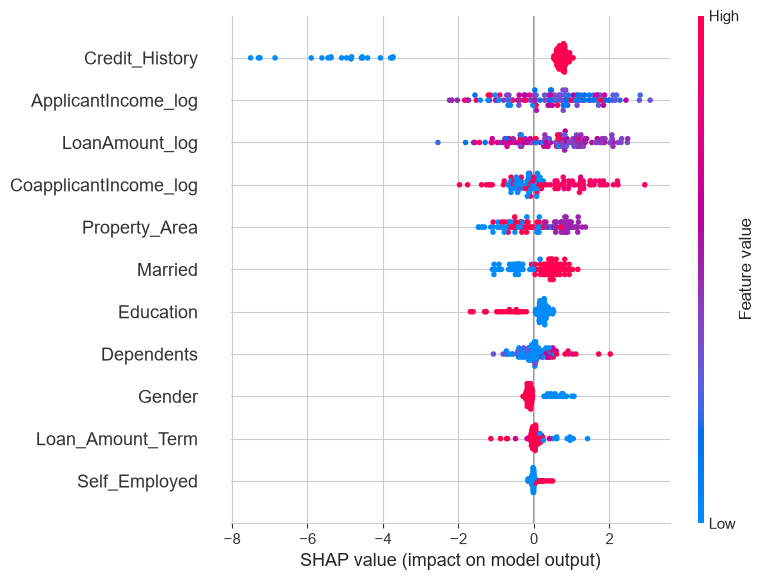

In [ ]:
import shap

explainer = shap.TreeExplainer(models['XGBoost'])
shap_values = explainer.shap_values(X_test_scaled)

shap.summary_plot(shap_values, X_test, feature_names=features, show=True)

"""L'analyse d'explicabilité par les valeurs de Shapley (SHAP Beeswarm Plot) éclaire la logique interne de XGBoost. 
Elle démontre une asymétrie décisionnelle majeure sur Credit_History : si un historique sain apporte un gain constant vers l'approbation, 
son absence génère une pénalité négative extrême (valeurs SHAP chutant jusqu'à $-7{,}5$), constituant un filtre quasi rédhibitoire.
 Les variables financières (ApplicantIncome_log, LoanAmount_log) agissent en second rideau pour moduler le risque sur les profils éligibles, 
 tandis que les attributs socio-démographiques
 (Gender, Self_Employed) présentent une contribution proche de zéro, attestant d'une dépendance minimale du modèle à ces variables"""